In [1]:
from MultiAgent_DQ import *
import numpy as np
from utils import *
import pandas as pd  
from tqdm import tqdm  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt

## Single Run

### Things I noticed:
with high delta is taking very long: more than 20mins to stop running and P_AC is not 1 but less


In [25]:
#critical deltas
epsilon_value = 0.1
lambda_value = 0.2
P, R, T, S = 0.2, 0.8, 1, 0
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))
print(f'critical delta 1 is {c1} and critical delta 2 is {c2}')

critical delta 1 is 0.2886002886002886 and critical delta 2 is 0.9661835748792271


In [28]:
M_value = 100
delta_value = 0.98

In [ ]:
algo = Algorithm(e=epsilon_value, lambda_val=lambda_value, 
                 alpha=0.05, delta=delta_value,
                 random_uniform=False, tolerance=1e-7, 
                 M=M_value, verbose=False)
q1_history_per_sample, q2_history_per_sample = algo.run()
dfs_1  = convert_dict_to_mean_df(q1_history_per_sample, mean= False)
dfs_2  = convert_dict_to_mean_df(q2_history_per_sample, mean= False)
strategy_played_1 = {}
strategy_played_2 = {}

# Iterate over the dataframe rows
for i in range(len(dfs_1)):
    last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc (optimized)
    last_2 = dfs_2[i].iloc[-1]  # Same for second dataframe

    # Define conditions for both players
    GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
    AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
    AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

    GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
    AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
    AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

    # Assign strategy for both players
    strategy_map = {
        AD_1: 1,  # Always Defecting
        GT_1: 2,  # Grim Trigger
        AC_1: 3,  # Always Cooperating
    }

    # Handle strategy for player 1 and player 2
    for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
        if player:
            strategy_played_1[i] = strategy[player]
            break  # Once a strategy is found, break the loop to avoid multiple assignments

    for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
        if player:
            strategy_played_2[i] = strategy[player]
            break  # Once a strategy is found, break the loop to avoid multiple assignments

# Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

# Merge the two DataFrames on 'Index'
df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

# Optionally, set 'Index' as the DataFrame index (if you need it)
df_merged.set_index('Index', inplace=True)
# Count how many times Strategy_1 and Strategy_2 are different
count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

# Display the result
print(f"Number of times Strategy_1 and Strategy_2 are different: {count_diff}")
# Count how many times both Strategy_1 and Strategy_2 have the value 1
P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum()/M_value

# Count how many times both Strategy_1 and Strategy_2 have the value 2
P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum()/M_value

# Display the results
print(f"P_AD: {P_AD}")
print(f"P_GT: {P_GT}")
# Count how many times Strategy_1 and Strategy_2 are different
count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()/M_value

# Display the result
print(f"Number of times Strategy_1 and Strategy_2 are different (NO CONVERGENCE): {count_diff}")


Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to timeout.
Stopping outer while loop due to t

In [18]:
P_AC = (1-(P_AD+P_GT)).round(4)
P_AC

np.float64(0.17)

## Simulation

In [14]:
# For tracking progress
M_value = 100
alpha_values = [0.05,0.1,0.2]
lambda_values = [0.05,0.1,0.2]
delta_values = [0.5,0.6,0.7]  # 1000 equally spaced values from 0 to 0.999
epsilon_values = [0.05,0.1,0.2]  # 1000 equally spaced values from 0 to 0.99
random_uniform_values = [False]

# Store results
results = []

# Generate all parameter combinations
parameter_combinations = list(itertools.product(alpha_values, lambda_values, epsilon_values, delta_values, random_uniform_values))

# Iterate through each parameter combination with tqdm progress bar
for alpha, lambda_val, e, delta, random_uniform in tqdm(parameter_combinations, desc="Processing combinations"):
    # Initialize the algorithm with the current parameter combination
    algo = Algorithm(e=e, lambda_val=lambda_val, 
                     alpha=alpha, delta=delta,
                     random_uniform=random_uniform, tolerance=1e-5, 
                     M=M_value, verbose=False)

    # Run the algorithm
    q1_history_per_sample, q2_history_per_sample = algo.run()

    # Convert results to dataframes
    dfs_1 = convert_dict_to_mean_df(q1_history_per_sample, mean=False)
    dfs_2 = convert_dict_to_mean_df(q2_history_per_sample, mean=False)

    # Initialize strategies played
    strategy_played_1 = {}
    strategy_played_2 = {}

    # Iterate over the dataframe rows
    for i in range(len(dfs_1)):
        last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc
        last_2 = dfs_2[i].iloc[-1]

        # Define conditions for both players
        GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

        GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

        # Assign strategy for both players
        strategy_map = {
            AD_1: 1,  # Always Defecting
            GT_1: 2,  # Grim Trigger
            AC_1: 3,  # Always Cooperating
        }

        for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
            if player:
                strategy_played_1[i] = strategy[player]
                break

        for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
            if player:
                strategy_played_2[i] = strategy[player]
                break

    # Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
    df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
    df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

    # Merge the two DataFrames on 'Index'
    df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

    # Optionally, set 'Index' as the DataFrame index (if you need it)
    df_merged.set_index('Index', inplace=True)

    # Count how many times Strategy_1 and Strategy_2 are different
    count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

    # Count how many times both Strategy_1 and Strategy_2 have the value 1
    P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum() / M_value

    # Count how many times both Strategy_1 and Strategy_2 have the value 2
    P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum() / M_value

    # Store results for this parameter combination
    results.append({
        'alpha': alpha,
        'lambda': lambda_val,
        'e': e,
        'delta': delta,
        'random_uniform': random_uniform,
        'P_AD': P_AD,
        'P_GT': P_GT,
        'nonconv': count_diff
    })

# Optionally, save results to a file
results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)


Processing combinations: 100%|██████████| 81/81 [02:09<00:00,  1.60s/it]


## Analysis

In [2]:
df = pd.read_csv("result_1_correct.csv")
df


,alpha,lambda,e,delta,random_uniform,P_AD,P_GT
0,0.05,0.05,0.05,0.010000,False,1.0,0.0
1,0.05,0.05,0.05,0.043793,False,1.0,0.0
2,0.05,0.05,0.05,0.077586,False,1.0,0.0
3,0.05,0.05,0.05,0.111379,False,1.0,0.0
4,0.05,0.05,0.05,0.145172,False,1.0,0.0
...,...,...,...,...,...,...,...
8095,0.20,0.20,0.79,0.854828,False,1.0,0.0
8096,0.20,0.20,0.79,0.888621,False,1.0,0.0
8097,0.20,0.20,0.79,0.922414,False,1.0,0.0
8098,0.20,0.20,0.79,0.956207,False,1.0,0.0


<Axes: >

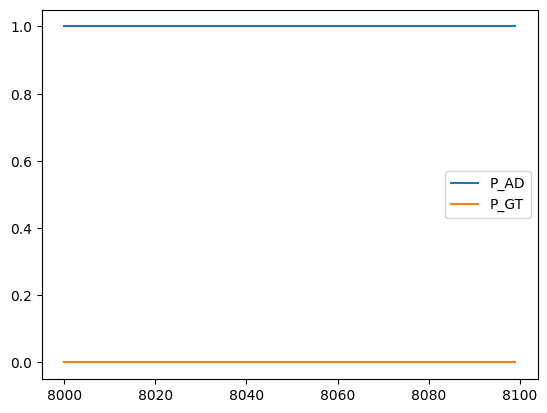

In [3]:
df[['P_AD', 'P_GT']].tail(100).plot()

In [4]:
df['delta'] = df['delta'].round(3)
df['e'] = df['e'].round(3)

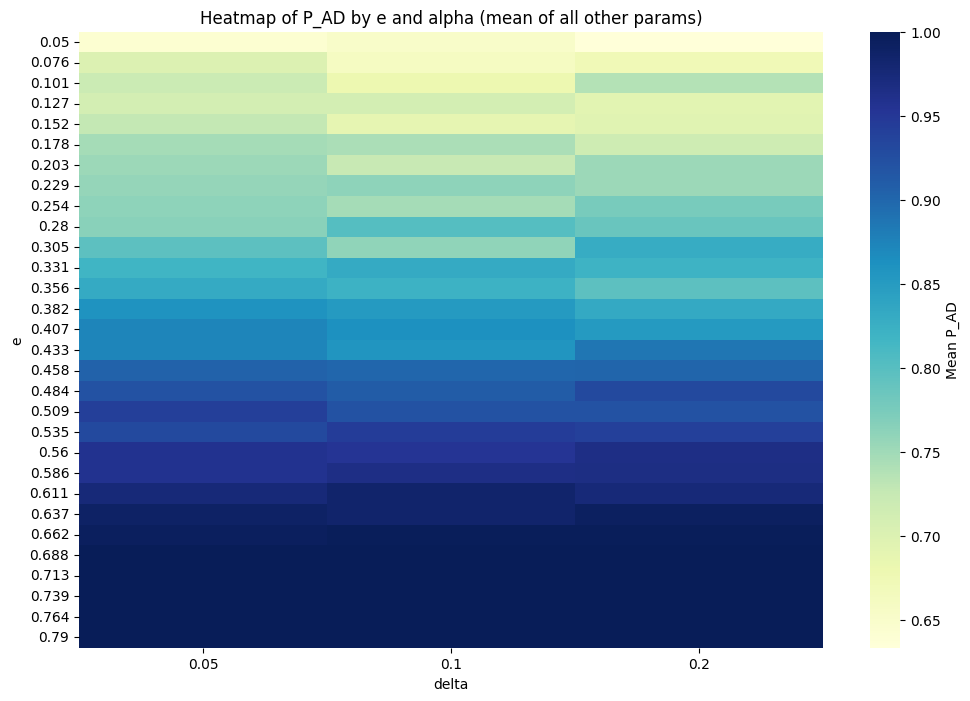

In [6]:
heatmap_mean(df, 'e', 'alpha', 'P_AD')


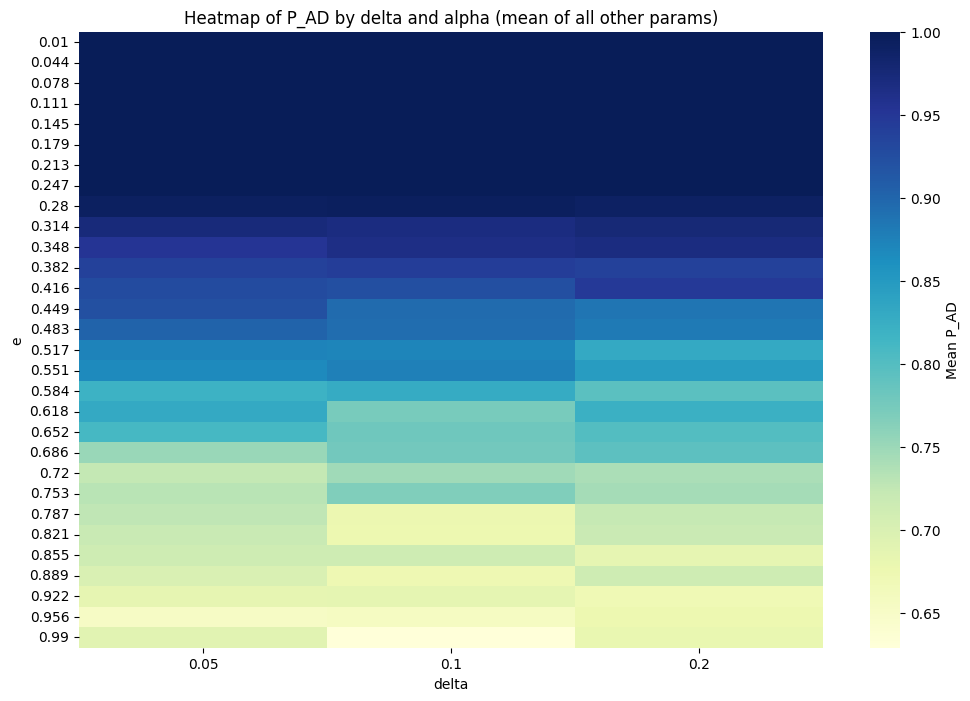

In [7]:
heatmap_mean(df, 'delta', 'alpha', 'P_AD')

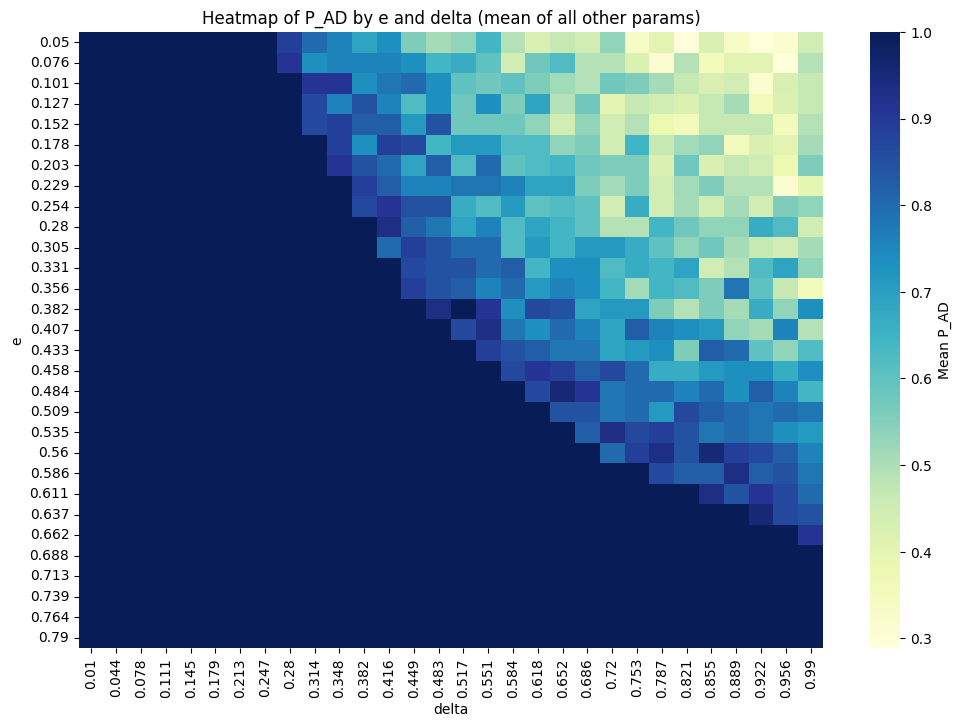

In [8]:
heatmap_mean(df, 'e', 'delta', 'P_AD')

In [9]:
for i in df.columns:
    print('                           ')
    print(f'{str(i)}: {df[i].unique()}')

                           
alpha: [0.05 0.1  0.2 ]
                           
lambda: [0.05 0.1  0.2 ]
                           
e: [0.05  0.076 0.101 0.127 0.152 0.178 0.203 0.229 0.254 0.28  0.305 0.331
 0.356 0.382 0.407 0.433 0.458 0.484 0.509 0.535 0.56  0.586 0.611 0.637
 0.662 0.688 0.713 0.739 0.764 0.79 ]
                           
delta: [0.01  0.044 0.078 0.111 0.145 0.179 0.213 0.247 0.28  0.314 0.348 0.382
 0.416 0.449 0.483 0.517 0.551 0.584 0.618 0.652 0.686 0.72  0.753 0.787
 0.821 0.855 0.889 0.922 0.956 0.99 ]
                           
random_uniform: [False]
                           
P_AD: [1.  0.8 0.2 0.4 0.6 0. ]
                           
P_GT: [0.  0.2 0.8 0.6 0.4 1. ]


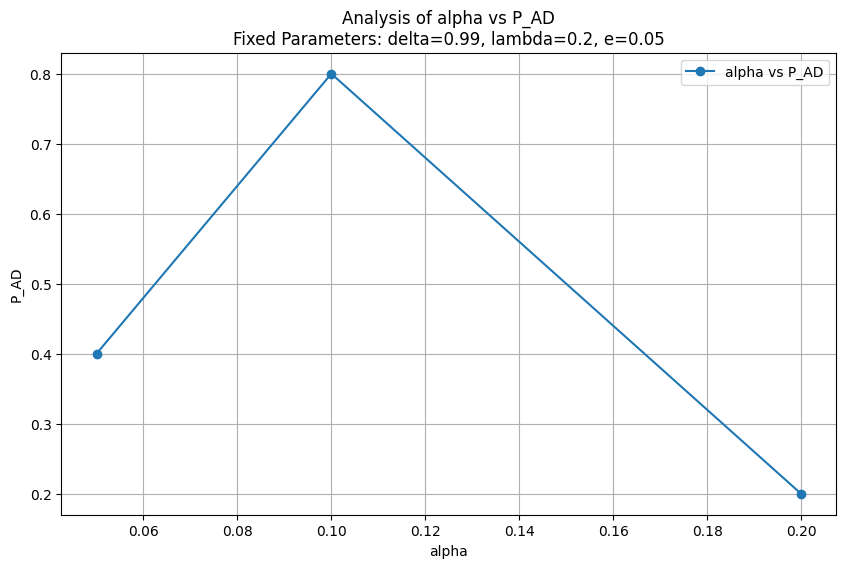

In [16]:
plot_analysis(
    df=df, 
    fixed_vars={'delta': 0.99, 'lambda': 0.2, 'e':0.05}, 
    x_var='alpha'
)
